# OpenClassrooms - parcours Data Analyst Business Intelligence - P8

# Milestone 1 - Analyse des données

Dans cette partie nous allons analyser le jeu de données que nous avons à notre disposition. Notre objectif est de comprendre les relations entre les variables, et surtout, celles qui influent sur le prix des transactions immobilières. Grâce à ce travail, nous pourrons ne conserver que les variables qui seront utiles à l'apprentissage de notre algorithme.

## 1.Type des données

La première étape à réaliser est d'importer les données dans le notebook et d'opérer des transformations sur les variables si celles-ci s'imposent (exemple : nettoyage ou changement de type des variables, etc.).

In [1]:
#On importe les librairies que nous utiliserons pour traiter les données et les visualiser
import pandas as pd, numpy as np
import scipy, sklearn
print("tout est bon !")
# N'oubliez pas d'avoir installé les librairies pandas, numpy et matplotlib via la commande pip

tout est bon !


In [2]:
#On importe les données dans un dataframe
df = pd.read_excel('historique_immobilier_paris_2017_2021_vdef2.xlsx')

In [3]:
# Vérification de la qualité des données
print('Valeurs manquantes :', df.isnull().sum().sum())
print('Doublons exacts :', df.duplicated().sum())
print('Prix négatifs ou nuls :', (df['valeur_fonciere'] <= 0).sum())
print('Surfaces négatives ou nulles :', (df['surface_reelle'] <= 0).sum())
print('Codes postaux hors Paris :', len(set(df['code_postal'].unique()) - set(range(75001, 75021))))

df = df.drop_duplicates()
print('Nombre de lignes après suppression des doublons :', len(df))

Valeurs manquantes : 0
Doublons exacts : 16
Prix négatifs ou nuls : 0
Surfaces négatives ou nulles : 0
Codes postaux hors Paris : 0
Nombre de lignes après suppression des doublons : 26180


Nous avons vérifié la qualité des données avant analyse : aucune valeur manquante, aucun prix ou surface négatif ou nul, aucun code postal hors de Paris. Nous avons identifié 16 lignes strictement dupliquées, supprimées avant l'analyse. Nous avons également repéré 2 biens avec une surface supérieure à 500 m² (jusqu'à 855 m2). 
Des valeurs extrêmes conservées dans l'analyse faute de pouvoir vérifier leur exactitude, mais qui constituent un point de vigilance sur la distribution de la surface.

Attention, si l'opération ci-dessus ne marche pas, il se peut que le package "openpyxl" ne soit pas présent sur votre ordinateur. Si c'est le cas vous pouvez l'installer en éxécutant la commande : pip install openpyxl ou conda install openpyxl.

In [4]:
#On vérifie que le type des données attribué par pandas est cohérent
df.dtypes

date_mutation       datetime64[ns]
valeur_fonciere            float64
adresse_numero               int64
adresse_nom_voie            object
code_postal                  int64
nom_commune                 object
code_type_local              int64
type_local                  object
surface_reelle               int64
dtype: object

### 2. Regardons les différents types de biens immobiliers que nous avons dans nos données :

In [5]:
print('la liste des différents types de biens immobiliers que nous avons dans les données est :')
print(df['type_local'].unique())
print(df['code_type_local'].unique())
df[['type_local', 'code_type_local']].drop_duplicates()

la liste des différents types de biens immobiliers que nous avons dans les données est :
['Appartement' 'Local industriel. commercial ou assimilé']
[2 4]


,type_local,code_type_local
0,Appartement,2
18,Local industriel. commercial ou assimilé,4


On observe qu'il y a 2 types de biens, et que leurs codes types sont 2 et 4.

### 3. Nombre de transactions

In [6]:
#On verifie le nombre de transactions que nous avons dans notre dataframe
print('le nombre de transactions dans les données est', len(df))
print('le nombre de transactions pour les appartements dans les données est', len(df[df['type_local'] == 'Appartement']))
print('le nombre de transactions pour les locaux commerciaux dans les données est', len(df[df['type_local'] == 'Local industriel. commercial ou assimilé']))

le nombre de transactions dans les données est 26180
le nombre de transactions pour les appartements dans les données est 24338
le nombre de transactions pour les locaux commerciaux dans les données est 1842


### 4. interval de l'historique des données

In [7]:
#On vérifie également la plage de l'historique disponible
print('la première date de transaction dans les données est le', df['date_mutation'].min())
print('la dernière date de transaction dans les données est le', df['date_mutation'].max())

la première date de transaction dans les données est le 2017-01-02 00:00:00
la dernière date de transaction dans les données est le 2021-12-31 00:00:00


## Commençons à analyser les données

Maintenant nous allons analyser les données historiques pour les 2 différents types de biens immobiliers en essayant d'identifier les relations entre les variables. Mais avant cela, il nous faudra pouvoir comparer les biens entre eux, et pour cela nous allons créer une colonne du prix au metre carré.

In [8]:
# Calcul de la colonne
df['prix_m2'] = df['valeur_fonciere'] / df['surface_reelle']
df.head()

,date_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,nom_commune,code_type_local,type_local,surface_reelle,prix_m2
0,2017-01-03,5.505597e+05,8,RUE DES COUTURES SAINT GERVAIS,75003,Paris 3e Arrondissement,2,Appartement,50,11011.193562
1,2017-01-12,1.576492e+06,32,AV MARCEAU,75008,Paris 8e Arrondissement,2,Appartement,163,9671.732877
2,2017-01-10,6.577574e+05,52,RUE DU FAUBOURG SAINT HONORE,75008,Paris 8e Arrondissement,2,Appartement,66,9966.020548
3,2017-01-10,2.500868e+05,64,RUE DU VERTBOIS,75003,Paris 3e Arrondissement,2,Appartement,22,11367.582877
4,2017-01-13,1.762667e+05,25,RUE DES LAVANDIERES STE OPPORT,75001,Paris 1er Arrondissement,2,Appartement,15,11751.113836


Maintenant, analysons les appartements.

### 5. Evolution du prix au metre carré des appartements dans Paris

In [9]:
#On retire les colonnes qui sont à priori inutiles ET nous allons nous concentrer sur les appartements dans un premier temps
appart = df[df['type_local'] == 'Appartement'][['date_mutation', 'surface_reelle', 'prix_m2', 'type_local']]

In [10]:
#Préparons un dataframe en regroupant les prix moyens de ventes des appartements par année avec la surface moyenne associée
prix_moyen_par_annee = appart.groupby(appart['date_mutation'].dt.year)[['surface_reelle', 'prix_m2']].mean()
prix_moyen_par_annee

,surface_reelle,prix_m2
date_mutation,,
2017,44.628533,9492.444883
2018,44.271671,10031.403432
2019,43.374452,10562.464260
2020,42.911472,10675.341817
2021,43.479864,10455.600126


On constate sur la moyenne des prix de vente des appartements à Paris que le prix a fortement augmenté entre 2017 et 2020, avant un léger recul en 2021, probablement lié aux effets du Covid sur le marché immobilier parisien. Nous allons créer un graphique pour mieux le visualiser.

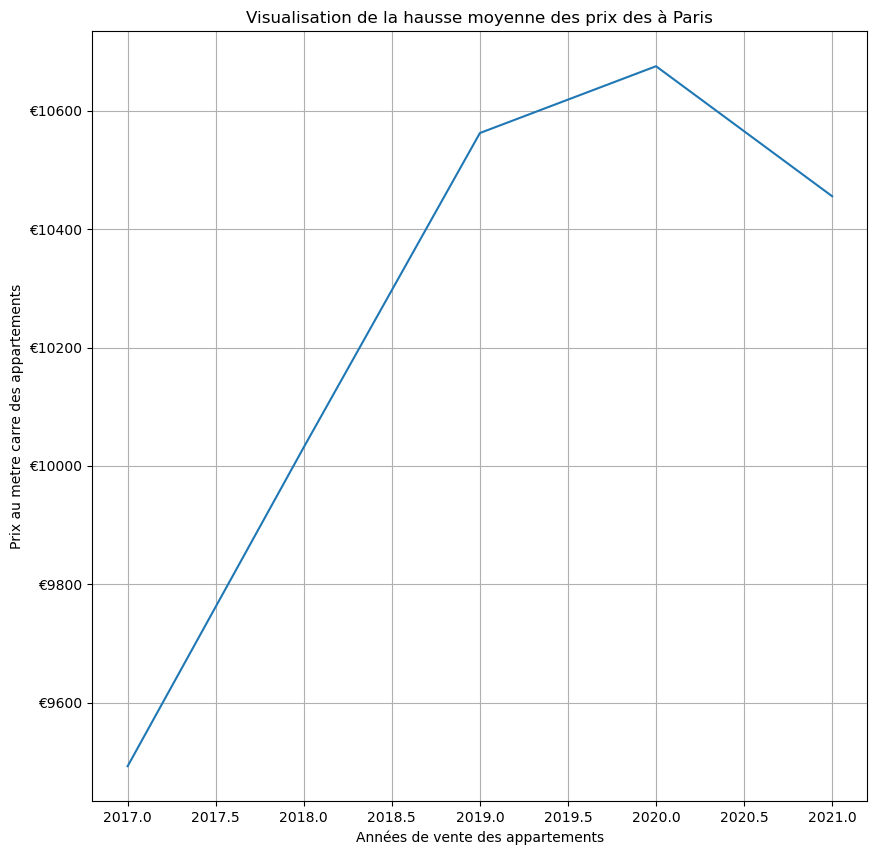

In [11]:
# Création d'un graphique pour visualiser la hausse de la moyenne des prix
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
plt.figure(figsize=(10,10))
plt.plot(prix_moyen_par_annee.index, prix_moyen_par_annee['prix_m2'])  
plt.xlabel('Années de vente des appartements')
plt.ylabel('Prix au metre carre des appartements')
formatter = ticker.FormatStrFormatter('€%d')
plt.gca().yaxis.set_major_formatter(formatter)
plt.grid()
plt.title('Visualisation de la hausse moyenne des prix des à Paris')
plt.show()

### 6. Différences de prix au metre carré entre les arrondissements

Maintenant nous allons chercher à afficher l'évolution des prix par arrondissement. Vérifions la liste des arrondissements que nous avons dans nos données. Normalement à Paris nous avons 20 codes postaux différents, 1 par arrondissement allant de 75001 à 75020.

In [12]:
#Liste des codes postaux dans nos données.
print('la liste des codes postaux dans les données est :')
print(df['code_postal'].unique())


la liste des codes postaux dans les données est :
[75003 75008 75001 75006 75005 75007 75010 75009 75011 75012 75013 75014
 75015 75016 75017 75018 75020 75019 75004 75002]


In [13]:
#Créeons un dataframe pour une deuxième visualisation avec l'evolution des prix par arrondissement
appart = df[df['type_local'] == 'Appartement'][['date_mutation', 'code_postal', 'surface_reelle', 'prix_m2', 'type_local']]
prix_moyen_par_arrondissement = appart.groupby(appart['code_postal'])[['surface_reelle', 'prix_m2']].mean()
prix_moyen_par_arrondissement

,surface_reelle,prix_m2
code_postal,,
75001,43.320293,12833.901606
75002,39.456456,11667.515820
75003,41.227331,12465.520343
75004,43.565693,13123.567058
75005,37.504831,12296.141322
75006,51.000000,13143.507482
75007,56.887974,12649.297681
75008,66.845295,10949.644835
75009,46.217975,10476.200594


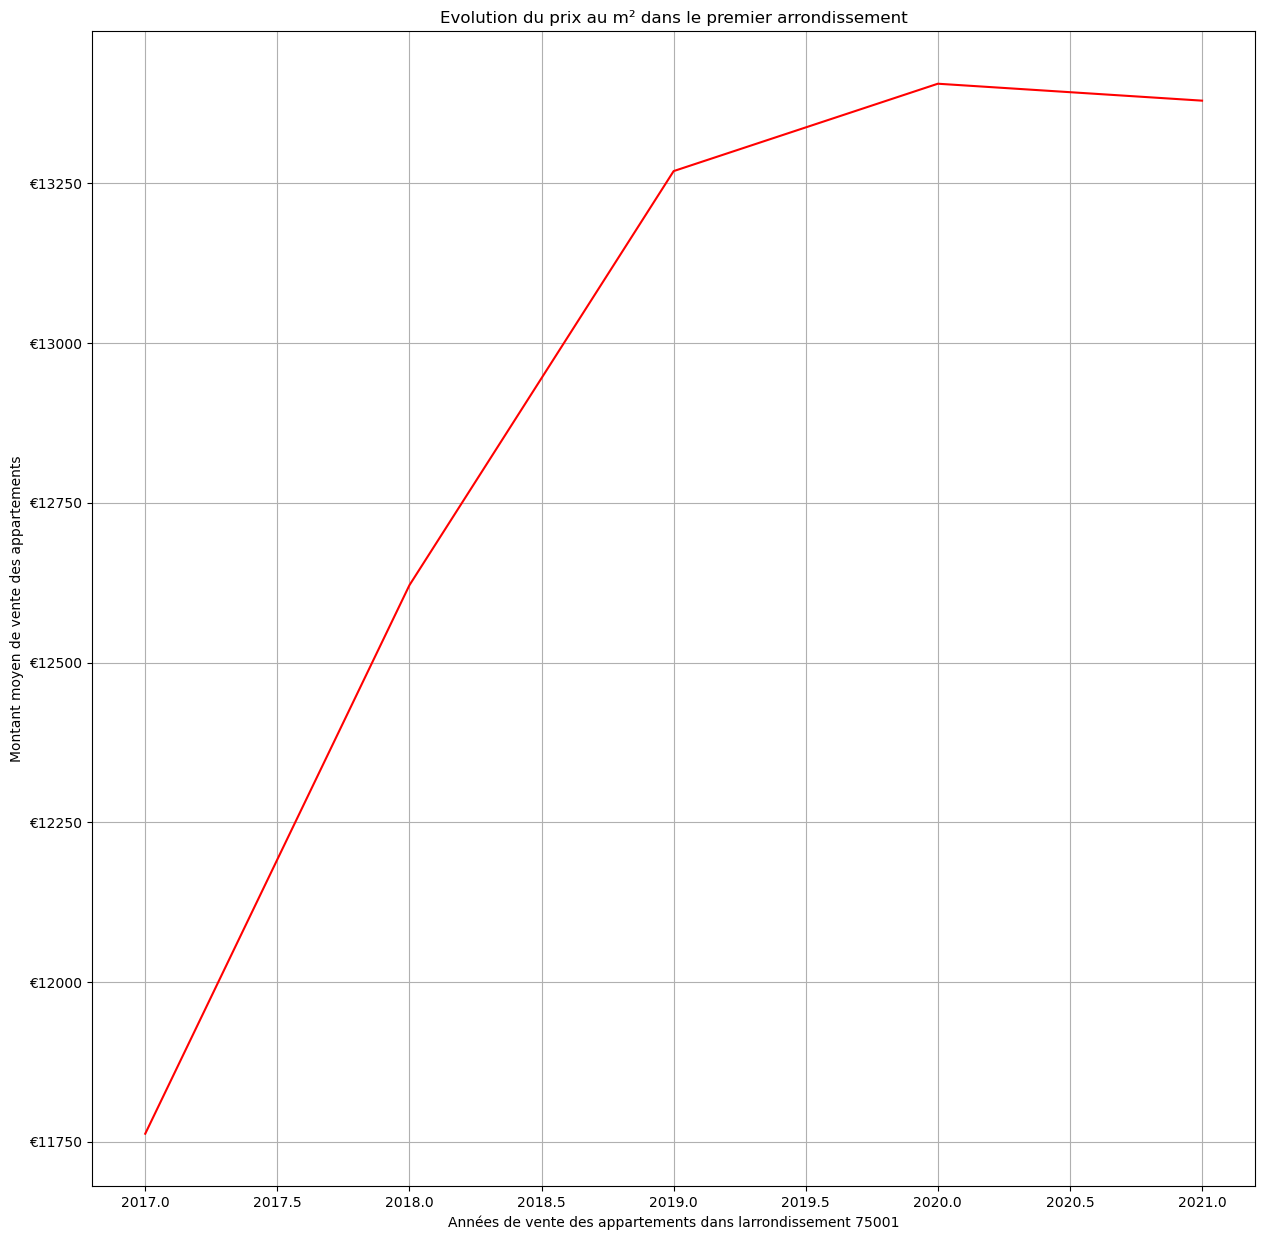

In [14]:
#Création d'un graphique pour visualiser la hausse de la moyenne des prix au metre carré dans le premier arrondissement
appart_75001 = appart[appart['code_postal'] == 75001]
prix_moyen_75001 = appart_75001.groupby(appart_75001['date_mutation'].dt.year)[['prix_m2']].mean()

plt.figure(figsize=(15,15))
plt.plot(prix_moyen_75001.index, prix_moyen_75001['prix_m2'], color='red')
plt.xlabel('Années de vente des appartements dans larrondissement 75001')
plt.ylabel('Montant moyen de vente des appartements')
formatter = ticker.FormatStrFormatter('€%d')
plt.gca().yaxis.set_major_formatter(formatter)
plt.grid()
plt.title('Evolution du prix au m² dans le premier arrondissement')
plt.show()

Nous allons ajouter à cette visualisation tous les autres arrondissement avec une couleur différente.

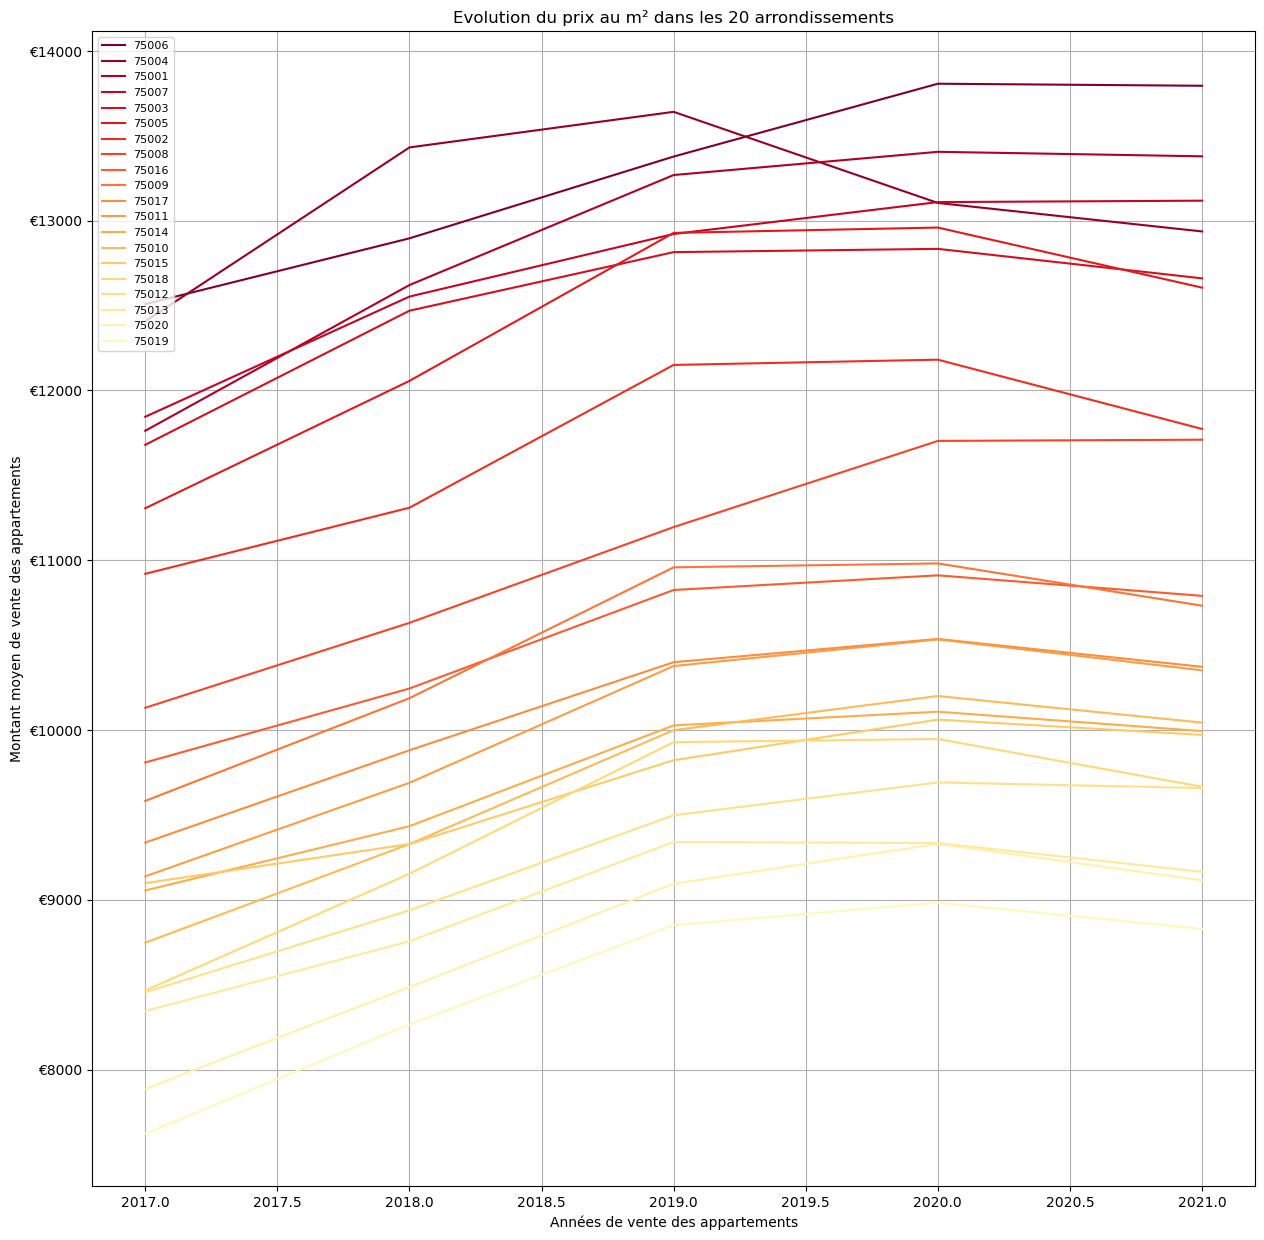

In [15]:
#On affiche l'évolution du prix au m² par arrondissement dans Paris
import matplotlib.cm as cm

plt.figure(figsize=(15,15))

# On trie du plus cher au moins cher, pour que la légende suive l'ordre visuel du graphique
arrondissements_tries = prix_moyen_par_arrondissement.sort_values('prix_m2', ascending=False).index

for i, cp in enumerate(arrondissements_tries):
    appart_cp = appart[appart['code_postal'] == cp]
    prix_moyen_cp = appart_cp.groupby(appart_cp['date_mutation'].dt.year)[['prix_m2']].mean()
    couleur = cm.YlOrRd(1 - i / len(arrondissements_tries))  # on inverse la position pour garder cher = rouge foncé
    plt.plot(prix_moyen_cp.index, prix_moyen_cp['prix_m2'], label=str(cp), color=couleur)

plt.xlabel('Années de vente des appartements')
plt.ylabel('Montant moyen de vente des appartements')
formatter = ticker.FormatStrFormatter('€%d')
plt.gca().yaxis.set_major_formatter(formatter)
plt.grid()
plt.title('Evolution du prix au m² dans les 20 arrondissements')
plt.legend(loc='upper left', fontsize=8)
plt.show()

On observe que globalement que tous les arrondissements suivent la même tendance de hausse des prix entre 2017 et 2020, avant un tassement en 2021. Les plus chers (75006, 75004, 75001, 75007) se situent autour de 12 000-13 000 €/m², contre 8 500-9 500 €/m² pour les moins chers (75019, 75020, 75013).

### 7. Prix au metre carré par transaction dans un arrondissement

In [16]:
#Vérifions le nombre de transaction dans le 6ème car le prix semble élevé
print('le nombre de transactions dans le 6ème arrondissement est', len(appart[appart['code_postal'] == 75006]))

le nombre de transactions dans le 6ème arrondissement est 709


On constate que le 6ème arrondissement compte 709 transactions sur la période, un nombre parmi les plus faibles des 20 arrondissements mais suffisant pour que son prix moyen élevé reflète une réalité du marché.





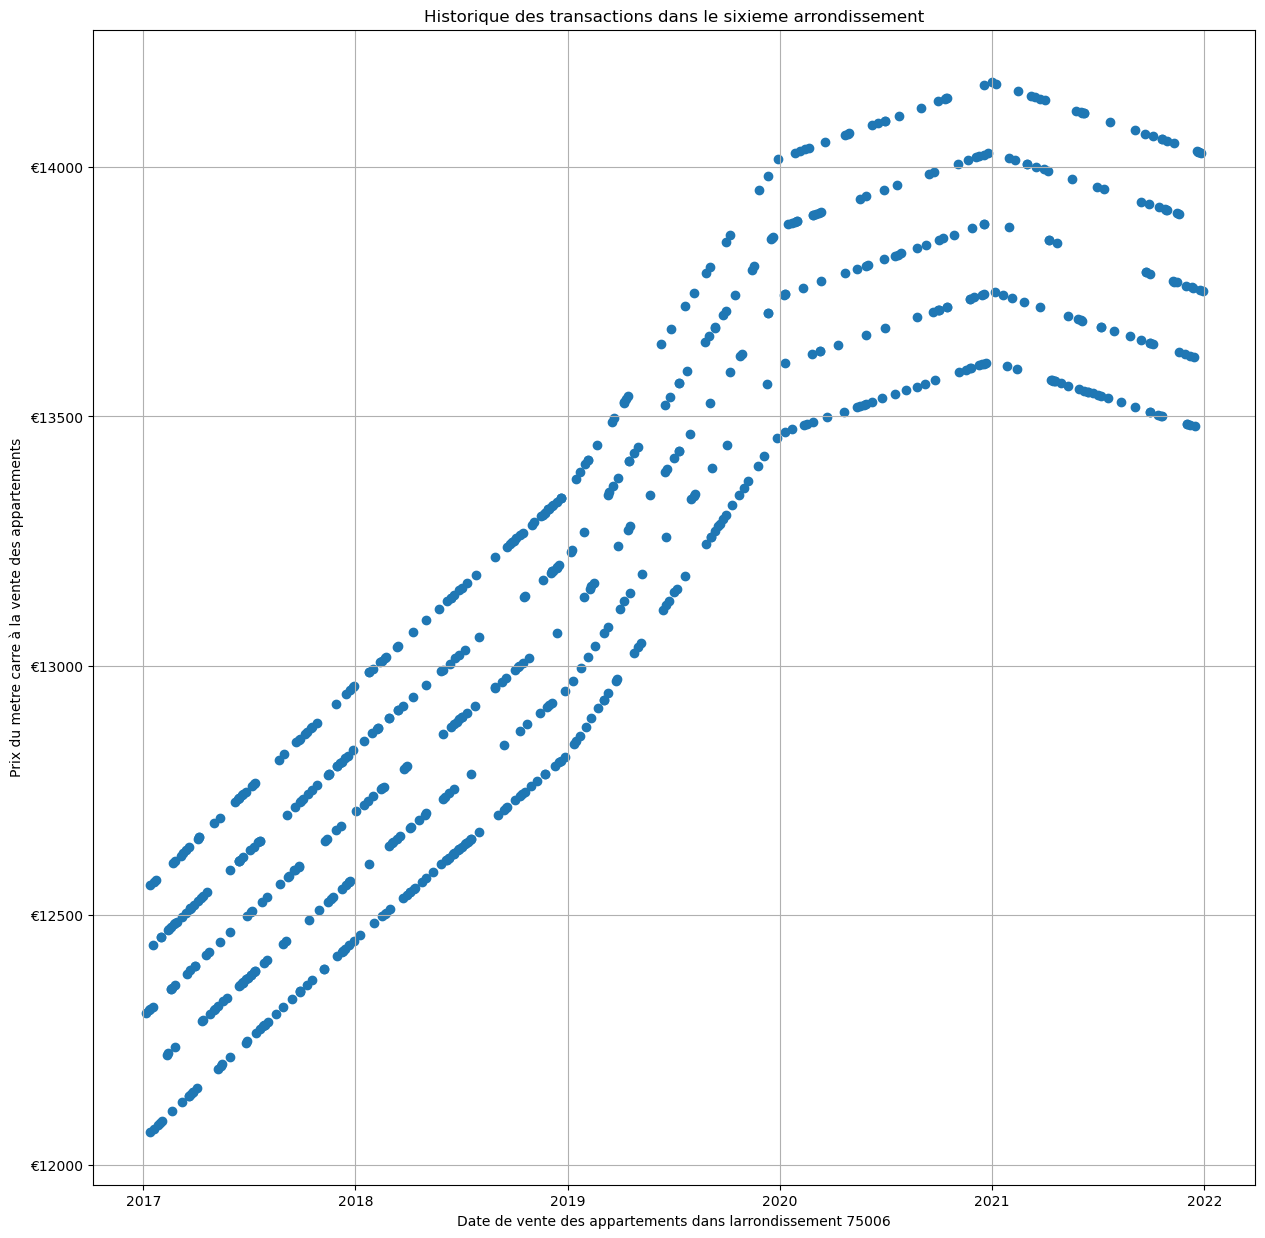

In [17]:
#Affichons l'historique des transactions pour visualiser la dispersion des données :
cp=75006
appart_cp = appart[appart['code_postal'] == cp]

plt.figure(figsize=(15,15))
#Insérer ci-dessous le scatter plot
plt.scatter(appart_cp['date_mutation'], appart_cp['prix_m2'])

plt.xlabel('Date de vente des appartements dans larrondissement 75006')
plt.ylabel('Prix du metre carre à la vente des appartements')
formatter = ticker.FormatStrFormatter('€%d')
plt.gca().yaxis.set_major_formatter(formatter)
plt.grid(which='both')
plt.title('Historique des transactions dans le sixieme arrondissement')
plt.show()

On observe une grande dispersion des prix, avec des groupes de points séparés, probablement des appartements de tailles différentes. Mais même avec cette dispersion, on voit toujours la même tendance. C'est que les prix montent, puis redescendent un peu en 2021.

Pour être sûres que cette tendance est réelle, on va faire un test statistique.

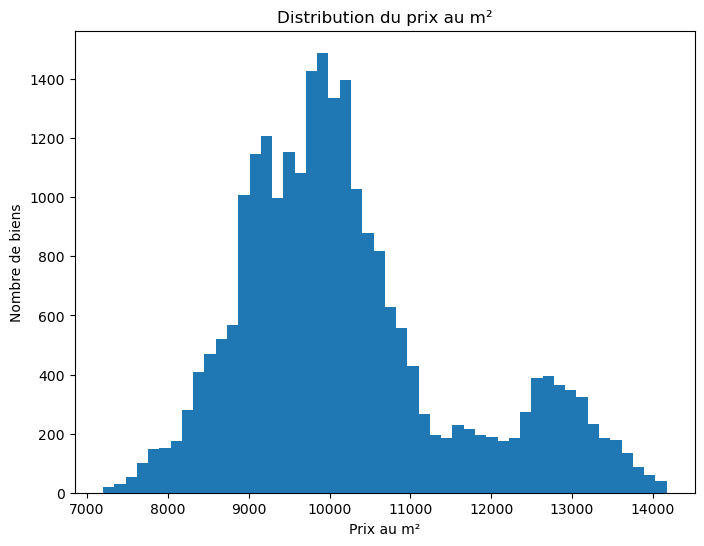

In [18]:
plt.figure(figsize=(8,6))
plt.hist(appart['prix_m2'], bins=50)
plt.xlabel('Prix au m²')
plt.ylabel('Nombre de biens')
plt.title('Distribution du prix au m²')
plt.show()

En regardant cet histogramme, le prix au m² ne suit pas une courbe en cloche classique. On utilise donc le test de Spearman plutôt que Pearson pour ce test de corrélation.

### 8. Vérification de la relation entre le prix au m² et la date dans le 6ème arrondissement par le calcul du coefficient de corrélation de Spearman 

Le prix au m² ne suit pas une distribution normale, nous utilisons donc Spearman. Ce qui nous intéresse, c'est de prouver que le temps a une influence sur le prix.

In [19]:
#On calcule la corrélation de Spearman
from scipy import stats

appart_cp = appart[appart['code_postal'] == cp].copy()
appart_cp['date_numerique'] = appart_cp['date_mutation'].apply(lambda x: x.toordinal())

coef_spearman, p_value = stats.spearmanr(appart_cp['date_numerique'], appart_cp['prix_m2'])
print('coefficient de corrélation :', coef_spearman)
print('p-value :', p_value)

coefficient de corrélation : 0.914844977318667
p-value : 1.1999820574655662e-280


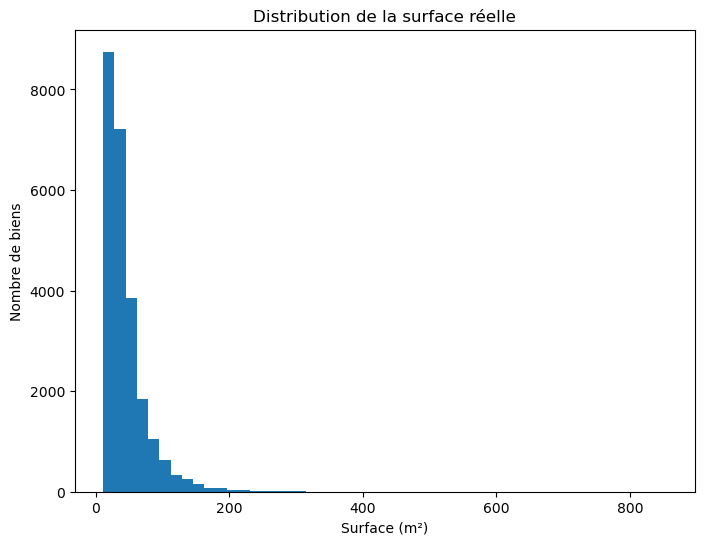

In [20]:
#histogramme de la surface uniquement

plt.figure(figsize=(8,6))
plt.hist(appart['surface_reelle'], bins=50)
plt.xlabel('Surface (m²)')
plt.ylabel('Nombre de biens')
plt.title('Distribution de la surface réelle')
plt.show()

La surface non plus ne suit pas une courbe en cloche : la plupart des biens sont petits, mais quelques-uns sont très grands, jusqu'à 855 m². On garde ces 2 biens dans l'analyse, faute de pouvoir vérifier leur exactitude. On utilise donc Spearman ici aussi.

Le coefficient de corrélation est de 0,91 avec une p-value extrêmement petite, donc nous pouvons confirmer la corrélation.

### 9. Vérification de la relation entre la valeur fonciere et la surface

In [21]:
coef_spearman_surface, p_value_surface = stats.spearmanr(appart['surface_reelle'], appart['prix_m2'])
print('coefficient de corrélation :', coef_spearman_surface)
print('p-value :', p_value_surface)

coefficient de corrélation : 0.0646692597086735
p-value : 5.5880966770195435e-24


Le coefficient de corrélation est de 0,065 avec une p-value extrêmement petite. La relation est statistiquement confirmée mais très faible

### 10. Analyse des locaux industriels, commerciaux et assimilés 

In [22]:
#On crée un dataset qui ne contient que les locaux commerciaux
locaux = df[df['type_local'] == 'Local industriel. commercial ou assimilé'][['date_mutation', 'surface_reelle', 'prix_m2', 'type_local']]

In [23]:
#Préparons un dataframe en regroupant les prix au metre carré moyens des ventes par année
prix_moyen_locaux_par_annee = locaux.groupby(locaux['date_mutation'].dt.year)[['surface_reelle', 'prix_m2']].mean()
prix_moyen_locaux_par_annee


,surface_reelle,prix_m2
date_mutation,,
2017,90.195402,10944.063022
2018,88.096866,11569.499180
2019,82.826389,11960.132050
2020,85.630952,11966.470204
2021,92.832000,12006.488691


Les locaux commerciaux se vendent systématiquement plus cher au m² que les appartements, 
chaque année, avec un écart d'environ 1 300 à 1 550 €/m². 
Et fait intéressant : contrairement aux appartements (qui reculent en 2021), le prix des locaux commerciaux continue d'augmenter en 2021
les deux segments ne réagissent pas pareil à la même période.

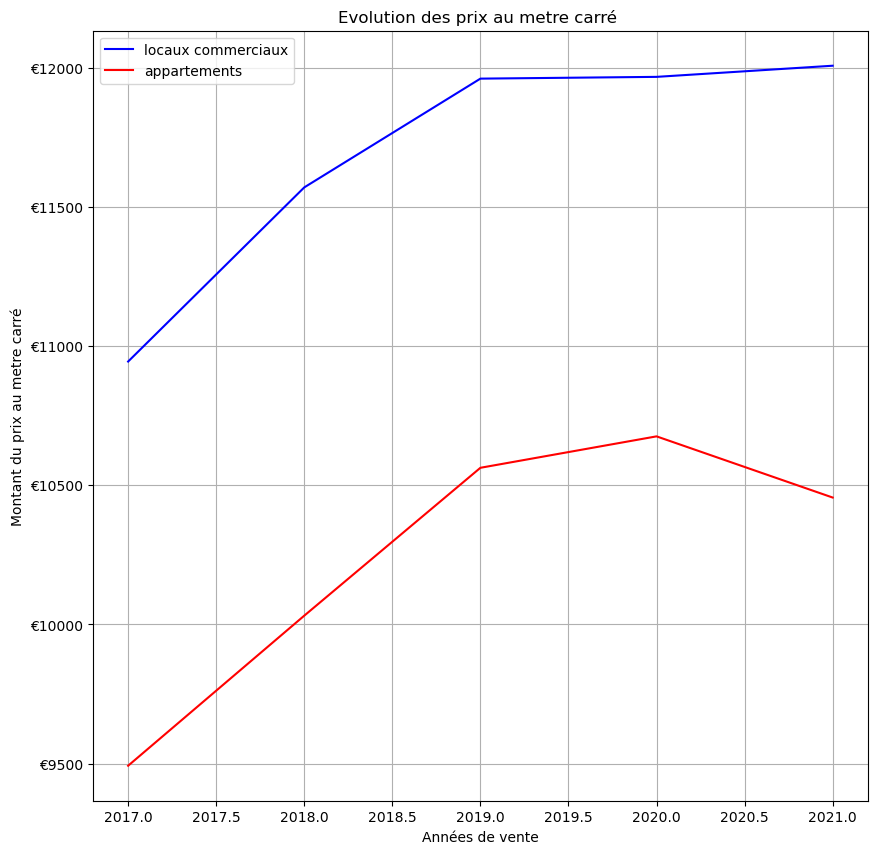

In [24]:
#Création d'un graphique pour visualiser la hausse de la moyenne des prix
plt.figure(figsize=(10,10))
plt.plot(prix_moyen_locaux_par_annee.index, prix_moyen_locaux_par_annee['prix_m2'], label='locaux commerciaux', color='blue')
plt.plot(prix_moyen_par_annee.index, prix_moyen_par_annee['prix_m2'], label='appartements', color='red')
plt.xlabel('Années de vente')
plt.ylabel('Montant du prix au metre carré')
plt.legend()
formatter = ticker.FormatStrFormatter('€%d')
plt.gca().yaxis.set_major_formatter(formatter)
plt.grid()
plt.title('Evolution des prix au metre carré ')
plt.show()

Le prix au mètre carré des locaux commerciaux est systématiquement supérieur à celui des appartements sur toute la période 2017-2021 (écart d'environ 1 300 à 1 550 €/m²). Fait notable : alors que le prix des appartements recule en 2021, celui des locaux commerciaux continue sa progression, ce qui suggère que les deux segments réagissent différemment aux mêmes conditions de marché.

Après ces analyses, nous pouvons conclure que les dimensions à utiliser pour prédire le prix au m² sont :

la surface du bien immobilier,
la date considérée,
la localisation (code_postal),
le type de bien.

# Milestone 2 - Entraînement de l'algorithme

Dans cette section nous allons maintenant entrâiner un algorithme à prédire la valeur fonciere d'un bien immobilier. Pour cela nous allons utiliser l'algorithme de régression linéaire.

On commence par préparer nos données en transformant les colonnes catégoriques du code postal et du type de local grâce au one hot encoder (sklearn) / get_dummies (pandas)

In [25]:
# On sélectionne les colonnes utiles identifiées dans la Milestone 1
df_ml = df[['surface_reelle', 'date_mutation', 'code_postal', 'type_local', 'valeur_fonciere']].copy()

# On convertit la date en nombre, comme au Point 8
df_ml['date_numerique'] = df_ml['date_mutation'].apply(lambda x: x.toordinal())
df_ml = df_ml.drop(columns=['date_mutation'])

# On transforme les colonnes catégoriques (code_postal, type_local) en 0/1 avec le one-hot encoding
df_ml = pd.get_dummies(df_ml, columns=['code_postal', 'type_local'])

df_ml.head()

,surface_reelle,valeur_fonciere,date_numerique,code_postal_75001,code_postal_75002,code_postal_75003,code_postal_75004,code_postal_75005,code_postal_75006,code_postal_75007,...,code_postal_75013,code_postal_75014,code_postal_75015,code_postal_75016,code_postal_75017,code_postal_75018,code_postal_75019,code_postal_75020,type_local_Appartement,type_local_Local industriel. commercial ou assimilé
0,50,5.505597e+05,736332,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
1,163,1.576492e+06,736341,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,66,6.577574e+05,736339,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
3,22,2.500868e+05,736339,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,15,1.762667e+05,736342,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False


On utilise le train_test_split pour prélever un tiers de nos données (33%) et les garder de côté. Nous allons entraîner notre algorithme sur le reste des données et puis mesurer notre erreur moyenne en pourcentage de la valeur foncière

In [26]:
# On sépare le jeu de données entre echantillons d'apprentissage et de test 
# La valeur y à trouver est la valeur foncière
from sklearn.model_selection import train_test_split

X = df_ml.drop(columns=['valeur_fonciere'])
y = df_ml['valeur_fonciere']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [27]:
#conversion des données en str


In [28]:
from sklearn.linear_model import LinearRegression
#On entraîne l'algorithme ci-dessous et on effectue la prédiction

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

import numpy as np

erreur_pourcentage = np.abs((y_test - y_pred) / y_test) * 100
erreur_moyenne = erreur_pourcentage.mean()

print('Notre algorithme fait', round(erreur_moyenne, 2), '% d\'erreur en moyenne sur la prédiction de la valeur foncière.')

Notre algorithme fait 9.05 % d'erreur en moyenne sur la prédiction de la valeur foncière.


Mes conclusions et comment j'aurais pu aller plus loin :

Mon objectif était de me tromper de moins de 10%. Résultat : 9,05% d'erreur. Objectif atteint.

Mon outil trace une ligne droite pour deviner le prix. Mais dans la vraie vie, la relation entre taille et prix n'est pas toujours une ligne droite parfaite. Ça rend mon outil moins précis.

J'ai entraîné mon outil avec beaucoup plus d'appartements (24 338) que de locaux commerciaux (1 842). Sa prédiction sur les locaux commerciaux est donc moins fiable.

Pour améliorer mon travail, je pourrais ajouter d'autres informations utiles au prix, comme l'étage du bien.

# Milestone 3 - Prédiction définitive pour le client 

Nous avons récupéré le fichier avec le portefeuille des actifs de la société. Nous allons l'importer puis effectuer la prédiction et statuer sur la branche qui, selon notre prédiction, aura le plus de valeur à la date demandée c'est à dire au 31 décembre 2022.<br>
Petite précision, nous souhaitons continuer à utiliser la surface réelle pour faire les calculs et pas la surface carrez. 

In [29]:
#On importe les données dans un dataframe
portefeuille = pd.read_excel('portefeuille_actifs+(3).xlsx')
portefeuille.head()


,adresse_numero,adresse_nom_voie,code_postal,code_commune,nom_commune,surface_carrez,code_type_local,type_local,surface_reelle_bati,nombre_pieces_principales,longitude,latitude
0,127,RUE SAINT-DENIS,75001,75101,Paris 1er Arrondissement,16.41,2,Appartement,25,1,2.349593,48.863227
1,62,RUE NOTRE-DAME DE NAZARETH,75003,75103,Paris 3e Arrondissement,20.47,2,Appartement,22,1,2.356977,48.867907
2,62,RUE DE TURENNE,75003,75103,Paris 3e Arrondissement,64.48,2,Appartement,65,3,2.364855,48.859318
3,32,AV GEORGE V,75008,75108,Paris 8e Arrondissement,63.29,2,Appartement,74,2,2.301586,48.868893
4,152,BD HAUSSMANN,75008,75108,Paris 8e Arrondissement,20.58,2,Appartement,22,1,2.311643,48.875490


Nous avons la liste des biens immobiliers de l'entreprise. Pour effectuer une prédiction, nous devons mettre ce fichier au même format que le dataframe que nous avons utilisé lors de l'entraînement de l'algorithme.

In [30]:
#On réutilise les mêmes fonctions pour faire le one hot encoding des variables catégorielles
portefeuille_ml = portefeuille[['surface_reelle_bati', 'code_postal', 'type_local']].copy()
portefeuille_ml = portefeuille_ml.rename(columns={'surface_reelle_bati': 'surface_reelle'})
portefeuille_ml = pd.get_dummies(portefeuille_ml, columns=['code_postal', 'type_local'])
portefeuille_ml = portefeuille_ml.reindex(columns=X.columns, fill_value=False)

#On importe la librairie datetime pour pouvoir créer une colonne timestamp avec la date du 31 décembre 2022 pour la prédiction
import datetime as dt
date_prediction = dt.datetime(2022, 12, 31)
portefeuille_ml['date_numerique'] = date_prediction.toordinal()


In [31]:
#Conversion du dataframe en str


Notre dataframe est prêt à être utilisé par notre algorithme de prédiction.

In [32]:
#On effectue la prédiction
predictions = model.predict(portefeuille_ml)
portefeuille['valeur_predite'] = predictions

#On vérifie les 10 premières valeurs
portefeuille[['adresse_nom_voie', 'code_postal', 'type_local', 'valeur_predite']].head(10)


,adresse_nom_voie,code_postal,type_local,valeur_predite
0,RUE SAINT-DENIS,75001,Appartement,438960.104513
1,RUE NOTRE-DAME DE NAZARETH,75003,Appartement,372953.479237
2,RUE DE TURENNE,75003,Appartement,822085.350456
3,AV GEORGE V,75008,Appartement,872150.168402
4,BD HAUSSMANN,75008,Appartement,329013.952044
5,BD HAUSSMANN,75008,Appartement,464798.006133
6,RUE DES GRAVILLIERS,75003,Appartement,393843.333712
7,RUE SAINT MAUR,75010,Appartement,640091.426146
8,RUE DE COURCELLES,75017,Appartement,148736.308902
9,RUE LAMARCK,75018,Appartement,147777.626263


Maintenant nous allons comparer la valorisation prédite pour les deux segments.

In [33]:
##### Valorisation du portefeuille sur le segment des particuliers
val_particulier = portefeuille.loc[portefeuille['type_local'] == 'Appartement', 'valeur_predite'].sum() / 1_000_000
print('la valorisation du segment particulier(appartements) est (en millions deuros):', round(val_particulier, 2))


la valorisation du segment particulier(appartements) est (en millions deuros): 71.23


In [34]:
#Valorisation du portefeuille sur le segment corporate
val_corporate = portefeuille.loc[portefeuille['type_local'] == 'Local industriel. commercial ou assimilé', 'valeur_predite'].sum() / 1_000_000
print('la valorisation du segment corporate(locaux commerciaux) est (en millions deuros):', round(val_corporate, 2))

la valorisation du segment corporate(locaux commerciaux) est (en millions deuros): 98.69


Mes conclusions sur le segment avec la plus grande valorisation et sur les limites de cette estimation :

Le segment corporate (locaux commerciaux) vaut plus cher que le segment particulier : 98,69 millions d'euros contre 71,23 millions. Et pourtant, il a moins de biens (121 contre 154). Je recommande donc de vendre en priorité une partie des appartements, puisque ce segment a le potentiel le plus faible.

Limites : mon outil se trompe en moyenne de 9,05%. Il a aussi appris avec beaucoup plus d'exemples d'appartements (24 338) que de locaux commerciaux (1 842). Sa prédiction sur les locaux commerciaux est donc probablement moins fiable.

# Milestone 4 - Classification des données issues du jeu de test

Dans cette partie nous allons labelliser automatiquement les biens immobiliers comme étant :
- soit des Appartements
- soit des Local industriel. commercial ou assimilé
Pour cela nous allons utiliser l'algorithme du KMeans sur le jeu de données partagé par l'entreprise.

Pour que l'algorithme fonctionne, il faut que nous préparions les données en supprimant les dimensions inutiles et en nous concentrant sur le facteur discriminant entre les appartements et les locaux commerciaux : la différence dans le prix au mètre carré tel que nous l'avons vu avant.

In [35]:
#On importe les données dans un dataframe
donnees_2021 = df[df['date_mutation'].dt.year == 2021].copy()
donnees_2021['prix_m2'] = donnees_2021['valeur_fonciere'] / donnees_2021['surface_reelle']
donnees_2021.head()

,date_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,nom_commune,code_type_local,type_local,surface_reelle,prix_m2
21128,2021-01-07,3.009804e+05,313,RUE DES TOURNELLES,75003,Paris 3e Arrondissement,2,Appartement,23,13086.103014
21129,2021-01-08,1.056941e+06,22,RUE JEAN GOUJON,75008,Paris 8e Arrondissement,2,Appartement,91,11614.734247
21130,2021-01-08,2.308898e+05,15,RUE BERANGER,75003,Paris 3e Arrondissement,2,Appartement,18,12827.212877
21131,2021-01-19,3.865867e+05,63,BD DE COURCELLES,75008,Paris 8e Arrondissement,2,Appartement,32,12080.835890
21132,2021-01-12,3.460434e+05,127,RUE SAINT-DENIS,75001,Paris 1er Arrondissement,2,Appartement,25,13841.735753


On applique les transformations nécessaires. Tout d'abord nous allons calculer le prix au mètre carré en divisant la valeur foncière par la surface. Ensuite nous allons retirer ces colonnes car nous avons déjà l'information qu'elles contiennent dans la dimension prix au mètre carré désormais.

Enfin toutes nos données sont de l'année 2021. Nous allons retirer cette dimension qui ne devrait pas être discriminante dans le regroupement des données.

In [36]:
donnees_kmeans = donnees_2021[['prix_m2']].copy()
donnees_kmeans.head()

,prix_m2
21128,13086.103014
21129,11614.734247
21130,12827.212877
21131,12080.835890
21132,13841.735753


Nous observons dans les données que nous avons des valeurs différentes de prix au mètre carré pour un même arrondissement (ici le 19ème arrondissement). Il se peut fort que cela soit notre dimension à utiliser pour attribuer les prix au mètre carré les plus élévé dans un département aux locaux commerciaux, et les prix les plus bas aux appartements.

Pour effectuer cette opération, nous allons utiliser l'algorithme du Kmeans qui va rechercher 2 centroïdes à travers les données.

In [37]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
donnees_2021['cluster'] = kmeans.fit_predict(donnees_kmeans)

In [38]:
# On vérifie les données de la prédiction
moyenne_prix_par_cluster = donnees_2021.groupby('cluster')['prix_m2'].mean()
print(moyenne_prix_par_cluster)

cluster
0    12738.128297
1     9986.745988
Name: prix_m2, dtype: float64


Nous avons obtenu notre prédiction. Nous pouvons changer les labels et remplacer les valeurs à 0 par Local industriel. commercial ou assimilé et les valeurs à +1 par Appartement. 

In [39]:
#On affiche les résultats
donnees_2021['type_local_predit'] = donnees_2021['cluster'].apply(
    lambda c: 'Local industriel. commercial ou assimilé' if c == 0 else 'Appartement'
)
precision = (donnees_2021['type_local_predit'] == donnees_2021['type_local']).mean() * 100
print("Précision du clustering par rapport aux vraies étiquettes :", round(precision, 2), "%")
donnees_2021[['prix_m2', 'type_local', 'type_local_predit']].head(10)

Précision du clustering par rapport aux vraies étiquettes : 79.87 %


,prix_m2,type_local,type_local_predit
21128,13086.103014,Appartement,Local industriel. commercial ou assimilé
21129,11614.734247,Appartement,Local industriel. commercial ou assimilé
21130,12827.212877,Appartement,Local industriel. commercial ou assimilé
21131,12080.835890,Appartement,Local industriel. commercial ou assimilé
21132,13841.735753,Appartement,Local industriel. commercial ou assimilé
21133,14631.603288,Local industriel. commercial ou assimilé,Local industriel. commercial ou assimilé
21134,11853.912055,Appartement,Local industriel. commercial ou assimilé
21135,12691.117808,Appartement,Local industriel. commercial ou assimilé
21136,13070.252329,Appartement,Local industriel. commercial ou assimilé
21137,11841.863014,Appartement,Local industriel. commercial ou assimilé


In [40]:
echantillon = pd.read_excel('echantillon_a_classer2.xlsx')
echantillon['prix_m2'] = echantillon['valeur_fonciere'] / echantillon['surface_reelle']
echantillon.head() 

,valeur_fonciere,code_postal,nom_commune,surface_reelle,prix_m2
0,868687.083271,75019,Paris 19e Arrondissement,88,9871.444128
1,452050.762192,75019,Paris 19e Arrondissement,45,10045.572493
2,193088.653587,75019,Paris 19e Arrondissement,21,9194.697790
3,303012.549370,75019,Paris 19e Arrondissement,32,9469.142168
4,149272.200110,75019,Paris 19e Arrondissement,20,7463.610005


In [41]:
echantillon['cluster'] = kmeans.predict(echantillon[['prix_m2']])
echantillon['type_local_predit'] = echantillon['cluster'].apply(
    lambda c: 'Local industriel. commercial ou assimilé' if c == 0 else 'Appartement'
)
echantillon[['code_postal', 'surface_reelle', 'prix_m2', 'type_local_predit']]

,code_postal,surface_reelle,prix_m2,type_local_predit
0,75019,88,9871.444128,Appartement
1,75019,45,10045.572493,Appartement
2,75019,21,9194.697790,Appartement
3,75019,32,9469.142168,Appartement
4,75019,20,7463.610005,Appartement
5,75019,18,9982.016919,Appartement
6,75019,25,9674.262777,Appartement
7,75019,63,7348.917415,Appartement
8,75019,53,9789.051438,Appartement
9,75019,53,7616.420959,Appartement


Sur les 40 biens envoyés par l'équipe de Louise, notre modèle n'a identifié aucun local commercial, tous ont été classés comme appartements. Ce résultat doit être interprété avec précaution : notre seuil de prix est calibré sur l'ensemble de Paris, alors que ces biens sont tous situés dans le même arrondissement (75019), plus abordable. Le modèle pourrait donc sous-estimer la présence de locaux commerciaux dans les quartiers moins chers.

# Milestone 5 - Analyse et présentation des résultats

Mes conclusions sur l'analyse et les limites de l'exercice :

Pour Maurice, j'ai trouvé 4 facteurs qui influencent le prix : la date, le quartier, le type de bien, et la surface. Avec ça, j'ai construit un outil qui se trompe de 9,05% en moyenne. En l'appliquant au patrimoine de l'entreprise, je recommande de vendre en priorité les appartements, dont la valeur prédite (71,23 M€) est plus faible que celle des locaux commerciaux (98,69 M€).

Pour Louise, j'ai testé mon outil de classification (79,87% de précision sur les données connues) sur les 40 opportunités qu'elle nous a transmises. Aucun local commercial n'a été détecté parmi ces biens. Ce résultat n'a pas pu être vérifié, faute de vraies réponses disponibles pour cet échantillon.

Plusieurs limites doivent être signalées : mon outil a appris avec beaucoup plus d'exemples d'appartements que de locaux commerciaux, donc ses prédictions sur ce segment sont moins fiables. Le seuil de prix utilisé pour la classification est calibré sur l'ensemble de Paris, ce qui peut sous-estimer les locaux commerciaux dans les quartiers moins chers, comme ceux de l'échantillon de Louise. Enfin, ma prédiction pour 2022 se base uniquement sur les tendances passées, sans connaître l'évolution réelle du marché depuis.